Libraries imported successfully!

Dataset Loaded Successfully!

First Five Rows:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185



Dataset Shape: (440, 8)

Column Names: ['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Statistical Summary:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


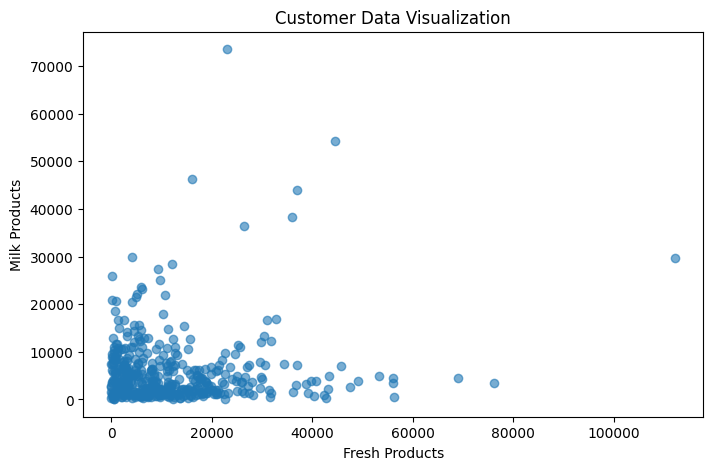


Data Standardised Successfully!

Cluster Centroids:
[[ 1.24280599e-02 -2.39839893e-01 -2.68484923e-01 -1.20948535e-03
  -2.54870598e-01 -9.51314940e-02]
 [-9.47944179e-02  1.82936703e+00  2.04785559e+00  9.22529021e-03
   1.94401299e+00  7.25610807e-01]]

Inertia: 1956.1242775222677


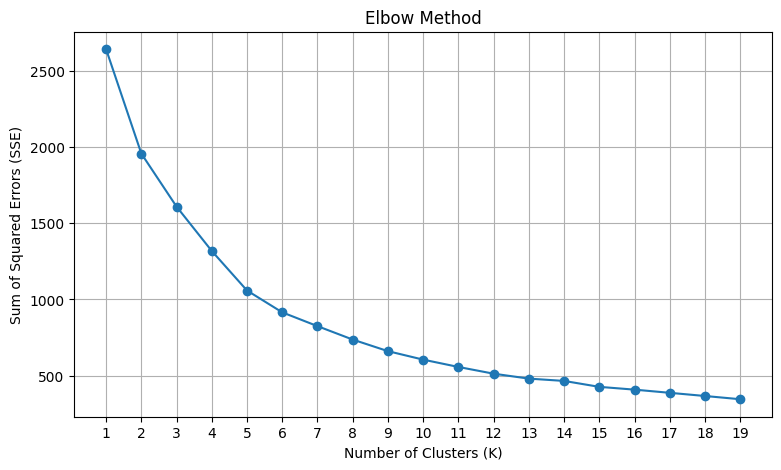


Final K-Means Model Trained Successfully!

Dataset with Cluster Labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,2,3,12669,9656,7561,214,2674,1338,0
1,2,3,7057,9810,9568,1762,3293,1776,3
2,2,3,6353,8808,7684,2405,3516,7844,3
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,2
5,2,3,9413,8259,5126,666,1795,1451,0
6,2,3,12126,3199,6975,480,3140,545,0
7,2,3,7579,4956,9426,1669,3321,2566,0
8,1,3,5963,3648,6192,425,1716,750,0
9,2,3,6006,11093,18881,1159,7425,2098,3



Number of Customers in Each Cluster:
Cluster
0    270
1     10
2     63
3     96
4      1
Name: count, dtype: int64


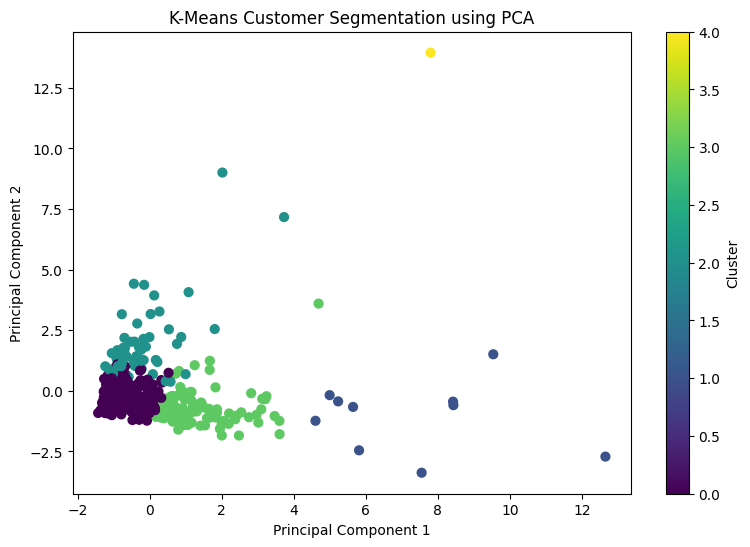


Cluster Summary:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,9092.16,2967.76,3807.41,2271.76,989.81,978.96
1,15964.90,34708.50,48536.90,3054.60,24875.20,2942.80
2,32957.98,4997.35,5884.76,8422.84,954.60,2462.97
3,5754.17,10866.60,16607.10,1464.12,7202.88,1813.39
4,36847.00,43950.00,20170.00,36534.00,239.00,47943.00



Clustering Completed Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================
# K-MEANS CLUSTERING - COMPLETE IMPLEMENTATION
# Dataset: Wholesale Customers (UCI)
# ============================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from google.colab import files

print("Libraries imported successfully!")

# 2. Load Dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
data = pd.read_csv(url)

print("\nDataset Loaded Successfully!")
print("\nFirst Five Rows:")
display(data.head())

# 3. Dataset Information
print("\nDataset Shape:", data.shape)
print("\nColumn Names:", list(data.columns))
print("\nDataset Information:")
data.info()

# 4. Check Missing Values
print("\nMissing Values:")
print(data.isnull().sum())

# 5. Statistical Summary
print("\nStatistical Summary:")
display(data.describe())

# 6. Visualise Original Data
plt.figure(figsize=(8, 5))
plt.scatter(data["Fresh"], data["Milk"], alpha=0.6)
plt.xlabel("Fresh Products")
plt.ylabel("Milk Products")
plt.title("Customer Data Visualization")
plt.show()

# 7. Select Spending Features
# Exclude Channel and Region because they are categorical variables.
features = [
    "Fresh", "Milk", "Grocery",
    "Frozen", "Detergents_Paper", "Delicassen"
]

X = data[features]

# 8. Standardise the Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nData Standardised Successfully!")

# 9. Apply K-Means with 2 Clusters
kmeans = KMeans(
    n_clusters=2,
    init="k-means++",
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

print("\nCluster Centroids:")
print(kmeans.cluster_centers_)

print("\nInertia:", kmeans.inertia_)

# 10. Elbow Method
SSE = []

for k in range(1, 20):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    SSE.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(range(1, 20), SSE, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.title("Elbow Method")
plt.xticks(range(1, 20))
plt.grid(True)
plt.show()

# 11. Train Final K-Means Model
# Change 5 if your Elbow graph suggests another K.
optimal_k = 5

final_model = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    random_state=42,
    n_init=10
)

clusters = final_model.fit_predict(X_scaled)

print("\nFinal K-Means Model Trained Successfully!")

# 12. Add Cluster Labels
result = data.copy()
result["Cluster"] = clusters

print("\nDataset with Cluster Labels:")
display(result.head(10))

# 13. Count Customers in Each Cluster
print("\nNumber of Customers in Each Cluster:")
print(result["Cluster"].value_counts().sort_index())

# 14. PCA Visualisation
pca = PCA(n_components=2)
reduced_data = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    reduced_data[:, 0],
    reduced_data[:, 1],
    c=clusters,
    cmap="viridis",
    s=40
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Customer Segmentation using PCA")
plt.colorbar(label="Cluster")
plt.show()

# 15. Cluster Summary
print("\nCluster Summary:")
display(result.groupby("Cluster")[features].mean().round(2))

# 16. Download Final Dataset
result.to_csv("KMeans_Clustered_Customers.csv", index=False)

print("\nClustering Completed Successfully!")
print("Downloading Clustered Dataset...")

files.download("KMeans_Clustered_Customers.csv")
